# 🚕 Taxis NYC — Preparación del modelo

## Serie horaria de demanda y primer modelo de pronóstico

**Proyecto:** AIMLF1 · Módulo 2  
**Integrante:** *Leonardo Isai Zepeda Tolentino*

---

### Objetivo de esta primera etapa

En esta primera fase se construirá la base técnica del proyecto:

1. Cargar los viajes oficiales de taxis amarillos de Nueva York correspondientes a enero de 2024.
2. Limpiar los registros y conservar únicamente viajes válidos.
3. Seleccionar las zonas con al menos **3,000 viajes durante el mes**.
4. Transformar los viajes individuales en una **serie horaria por zona**.
5. Completar explícitamente las horas sin viajes con valor `0`.
6. Construir un modelo base: **“igual que hace una semana”**.
7. Entrenar un primer modelo sencillo con **XGBoost**.
8. Evaluar ambos modelos respetando el orden temporal de los datos.
9. Exportar la información de las zonas que utilizará posteriormente el endpoint `/info` de FastAPI.

> En esta etapa todavía **no** se implementan los cuantiles definitivos, K-Means, PCA ni Streamlit. Primero se valida que la preparación de datos y el flujo de pronóstico funcionen correctamente.


## 1. Criterios metodológicos

Para mantener el análisis reproducible y evitar fuga de información se seguirán estas decisiones:

- **Semilla reproducible:** `RANDOM_STATE = 42`.
- **Entrenamiento:** datos disponibles hasta el **24 de enero de 2024**.
- **Prueba:** del **25 al 31 de enero de 2024**.
- **No se utiliza `train_test_split`**, porque el problema es temporal.
- El primer baseline será `lag_168`, equivalente a utilizar la demanda observada exactamente una semana antes.
- No se utilizan lags menores a 24 horas para un pronóstico del día siguiente.
- El conjunto de prueba se mantiene separado para medir el rendimiento real del modelo.

### ¿Por qué `random_state = 42`?

La semilla no se elige para obtener la mejor métrica. Su función es hacer reproducibles los procesos que contienen aleatoriedad, de modo que los integrantes del proyecto obtengan los mismos resultados cuando ejecuten el notebook nuevamente.


In [25]:
# ============================================================
# 0. INSTALACIÓN DE DEPENDENCIAS
# ============================================================
# Esta celda está pensada principalmente para Google Colab.
# Si las librerías ya están instaladas, pip simplemente validará
# o actualizará las dependencias necesarias.

%pip -q install xgboost pyarrow


In [26]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo inicial de Machine Learning
from xgboost import XGBRegressor

# Métricas de evaluación para regresión
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Configuración visual general
sns.set_theme(style="whitegrid")

# Semilla global para procesos con aleatoriedad.
# Se mantiene fija para garantizar reproducibilidad.
RANDOM_STATE = 42

print("Librerías importadas correctamente.")
print("RANDOM_STATE =", RANDOM_STATE)


Librerías importadas correctamente.
RANDOM_STATE = 42


## 2. Configuración general

En lugar de escribir fechas y límites repetidamente dentro del código, se definen como constantes al inicio del notebook. Esto facilita el mantenimiento y reduce errores.

Las reglas principales de esta actividad son:

- Solo se consideran viajes cuyo inicio ocurrió dentro de enero de 2024.
- La zona de un viaje corresponde a `PULocationID`.
- Para el pronóstico se consideran zonas con al menos **3,000 viajes** durante el mes.
- El conjunto de entrenamiento termina el **24 de enero**.
- El conjunto de prueba corresponde al período **25–31 de enero**.


In [27]:
# ============================================================
# 2. CONFIGURACIÓN GENERAL DEL PROYECTO
# ============================================================

# Dataset oficial de taxis amarillos de enero de 2024.
URL_VIAJES = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2024-01.parquet"
)

# Catálogo oficial con los nombres y distritos de las zonas.
URL_ZONAS = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "misc/taxi_zone_lookup.csv"
)

# Fechas del análisis.
FECHA_INICIO = pd.Timestamp("2024-01-01")
FECHA_FIN_ENERO = pd.Timestamp("2024-02-01")

# Inicio del conjunto de prueba.
# Todo lo anterior corresponde al entrenamiento.
FECHA_INICIO_TEST = pd.Timestamp("2024-01-25")

# Cantidad mínima de viajes para que una zona
# participe en el modelo de pronóstico.
MIN_VIAJES_PRONOSTICO = 3000

print("Configuración cargada correctamente.")


Configuración cargada correctamente.


## 3. Carga de los datos

Para construir la serie temporal únicamente se necesitan dos columnas del archivo principal:

- `tpep_pickup_datetime`: fecha y hora de inicio del viaje.
- `PULocationID`: identificador de la zona donde comenzó el viaje.

Leer únicamente estas columnas reduce el consumo de memoria RAM.

El catálogo de zonas se carga por separado para traducir los identificadores a nombres comprensibles.


In [28]:
# ============================================================
# 3. CARGA DE LOS DATOS
# ============================================================

# Columnas necesarias en esta primera etapa.
columnas_necesarias = [
    "tpep_pickup_datetime",
    "PULocationID"
]

# Leemos el archivo Parquet oficial.
# El formato Parquet permite seleccionar columnas y es más eficiente
# para datasets grandes que un CSV tradicional.
viajes = pd.read_parquet(
    URL_VIAJES,
    columns=columnas_necesarias
)

# Catálogo oficial de zonas de taxi.
zonas = pd.read_csv(URL_ZONAS)

print(f"Viajes cargados: {len(viajes):,}")
print(f"Zonas registradas en el catálogo: {len(zonas):,}")


Viajes cargados: 2,964,624
Zonas registradas en el catálogo: 265


In [29]:
# ============================================================
# 4. INSPECCIÓN INICIAL
# ============================================================

print("Primeros registros del dataset de viajes:")
display(viajes.head())

print("\nInformación general del dataset:")
viajes.info()

print("\nPrimeras zonas del catálogo:")
display(zonas.head())


Primeros registros del dataset de viajes:


,tpep_pickup_datetime,PULocationID
0,2024-01-01 00:57:55,186
1,2024-01-01 00:03:00,140
2,2024-01-01 00:17:06,236
3,2024-01-01 00:36:38,79
4,2024-01-01 00:46:51,211



Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 2 columns):
 #   Column                Dtype         
---  ------                -----         
 0   tpep_pickup_datetime  datetime64[us]
 1   PULocationID          int32         
dtypes: datetime64[us](1), int32(1)
memory usage: 33.9 MB

Primeras zonas del catálogo:


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


## 4. Limpieza temporal

Aunque el archivo corresponde a enero de 2024, se valida explícitamente la fecha de inicio de cada viaje.

Esto evita conservar registros cuya fecha pueda encontrarse fuera del período requerido.

También se utiliza `errors="coerce"` para convertir valores de fecha inválidos en `NaT`, de modo que puedan descartarse de forma segura.


In [30]:
# ============================================================
# 5. LIMPIEZA TEMPORAL
# ============================================================

# Convertimos la columna de fecha al tipo datetime.
viajes["tpep_pickup_datetime"] = pd.to_datetime(
    viajes["tpep_pickup_datetime"],
    errors="coerce"
)

viajes_antes = len(viajes)

# Conservamos únicamente viajes cuyo inicio ocurrió
# dentro de enero de 2024.
viajes = viajes[
    (viajes["tpep_pickup_datetime"] >= FECHA_INICIO) &
    (viajes["tpep_pickup_datetime"] < FECHA_FIN_ENERO)
].copy()

print(f"Registros antes del filtro: {viajes_antes:,}")
print(f"Viajes válidos de enero:    {len(viajes):,}")
print(f"Registros descartados:      {viajes_antes - len(viajes):,}")


Registros antes del filtro: 2,964,624
Viajes válidos de enero:    2,964,606
Registros descartados:      18


## 5. Incorporación del catálogo de zonas

La actividad define la zona de cada viaje mediante `PULocationID`, es decir, **la zona de origen**.

Se realiza un `merge` con el catálogo oficial para incorporar:

- nombre de la zona;
- distrito (`Borough`).

Posteriormente se eliminan las zonas sin identificación válida o denominadas `"Unknown"`.


In [31]:
# ============================================================
# 6. INCORPORACIÓN DEL CATÁLOGO DE ZONAS
# ============================================================

# Seleccionamos solo las columnas que necesitamos.
catalogo = zonas[
    ["LocationID", "Borough", "Zone"]
].copy()

# Relacionamos PULocationID con LocationID.
viajes = viajes.merge(
    catalogo,
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

# Renombramos las columnas para hacer el código más legible.
viajes = viajes.rename(
    columns={
        "Zone": "nombre_zona",
        "Borough": "distrito"
    }
)

# Eliminamos zonas sin nombre y las llamadas "Unknown".
viajes = viajes[
    viajes["nombre_zona"].notna() &
    (viajes["nombre_zona"].astype(str).str.strip().str.lower() != "unknown")
].copy()

print(f"Viajes después de eliminar zonas no identificadas: {len(viajes):,}")

display(
    viajes[
        [
            "tpep_pickup_datetime",
            "PULocationID",
            "nombre_zona",
            "distrito"
        ]
    ].head()
)


Viajes después de eliminar zonas no identificadas: 2,954,246


,tpep_pickup_datetime,PULocationID,nombre_zona,distrito
0,2024-01-01 00:57:55,186,Penn Station/Madison Sq West,Manhattan
1,2024-01-01 00:03:00,140,Lenox Hill East,Manhattan
2,2024-01-01 00:17:06,236,Upper East Side North,Manhattan
3,2024-01-01 00:36:38,79,East Village,Manhattan
4,2024-01-01 00:46:51,211,SoHo,Manhattan


## 6. Selección de zonas pronosticables

No todas las zonas tienen suficiente actividad para construir un modelo de demanda estable.

La regla del proyecto indica conservar para el pronóstico solamente aquellas zonas que registraron al menos **3,000 viajes durante enero**.


In [32]:
# ============================================================
# 7. CONTEO DE VIAJES POR ZONA
# ============================================================

conteo_zonas = (
    viajes.groupby(
        ["PULocationID", "nombre_zona", "distrito"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "total_viajes"})
)

# Aplicamos el límite mínimo establecido.
zonas_pronostico = conteo_zonas[
    conteo_zonas["total_viajes"] >= MIN_VIAJES_PRONOSTICO
].copy()

zonas_pronostico = zonas_pronostico.sort_values(
    "total_viajes",
    ascending=False
)

print(f"Zonas con al menos {MIN_VIAJES_PRONOSTICO:,} viajes: "
      f"{len(zonas_pronostico)}")

display(zonas_pronostico.head(15))


Zonas con al menos 3,000 viajes: 58


,PULocationID,nombre_zona,distrito,total_viajes
126,132,JFK Airport,Queens,145240
155,161,Midtown Center,Manhattan,143469
231,237,Upper East Side South,Manhattan,142707
230,236,Upper East Side North,Manhattan,136464
156,162,Midtown East,Manhattan,106717
224,230,Times Sq/Theatre District,Manhattan,106324
180,186,Penn Station/Madison Sq West,Manhattan,104522
136,142,Lincoln Square East,Manhattan,104080
132,138,LaGuardia Airport,Queens,89530
233,239,Upper West Side South,Manhattan,88474


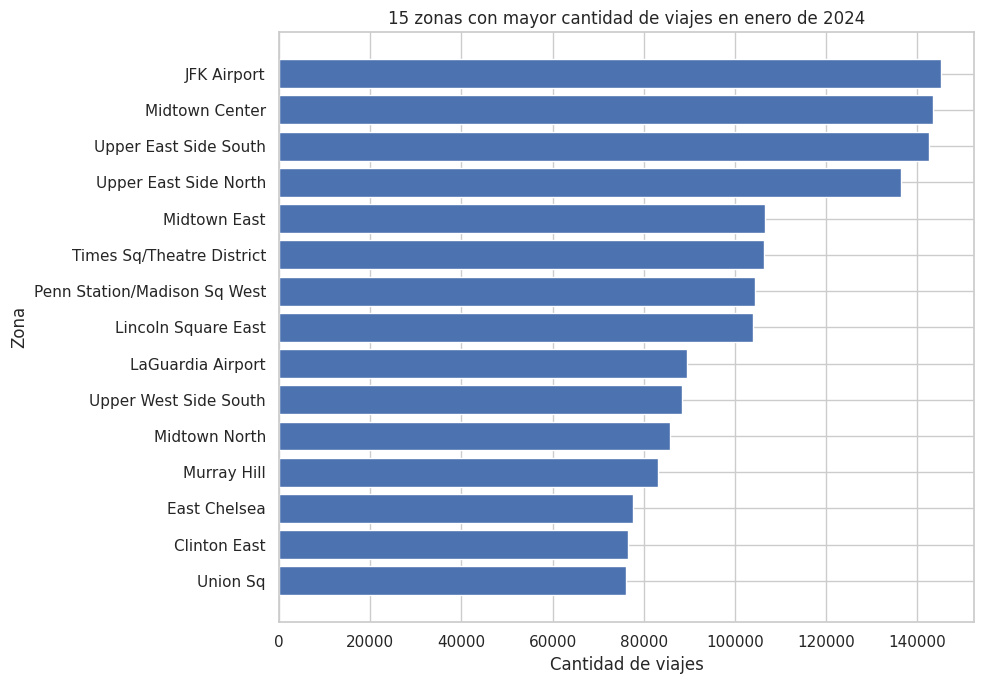

In [33]:
# ============================================================
# 8. VISUALIZACIÓN DE LAS ZONAS CON MAYOR DEMANDA
# ============================================================

top_zonas = zonas_pronostico.head(15).sort_values(
    "total_viajes",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_zonas["nombre_zona"],
    top_zonas["total_viajes"]
)
plt.title("15 zonas con mayor cantidad de viajes en enero de 2024")
plt.xlabel("Cantidad de viajes")
plt.ylabel("Zona")
plt.tight_layout()
plt.show()


## 7. Construcción de la serie horaria

Los viajes individuales deben convertirse en una serie temporal de demanda.

El procedimiento es:

1. Redondear la fecha de inicio hacia abajo a la hora completa.
2. Contar cuántos viajes comenzaron en cada zona durante cada hora.
3. Crear todas las combinaciones posibles entre zona y hora.
4. Asignar `0` cuando una combinación zona-hora no aparezca en los viajes observados.

Este último punto es importante: la ausencia de una fila no significa que la demanda sea desconocida; significa que durante esa hora hubo **cero viajes**.


In [34]:
# ============================================================
# 9. FILTRADO DE VIAJES PARA LAS ZONAS PRONOSTICABLES
# ============================================================

# Lista de identificadores que sí participarán en el modelo.
ids_zonas = zonas_pronostico["PULocationID"].tolist()

viajes_modelo = viajes[
    viajes["PULocationID"].isin(ids_zonas)
].copy()

print(f"Viajes que participarán en la serie horaria: "
      f"{len(viajes_modelo):,}")


Viajes que participarán en la serie horaria: 2,885,953


In [35]:
# ============================================================
# 10. AGRUPACIÓN POR ZONA Y HORA
# ============================================================

# floor("h") redondea la hora hacia abajo.
#
# Ejemplo:
# 2024-01-05 14:37:20 -> 2024-01-05 14:00:00
viajes_modelo["hora"] = (
    viajes_modelo["tpep_pickup_datetime"]
    .dt.floor("h")
)

# Contamos la cantidad de viajes en cada combinación zona-hora.
demanda_observada = (
    viajes_modelo
    .groupby(["PULocationID", "hora"])
    .size()
    .reset_index(name="viajes")
)

print(f"Combinaciones zona-hora observadas: "
      f"{len(demanda_observada):,}")

display(demanda_observada.head())


Combinaciones zona-hora observadas: 41,359


,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25
1,4,2024-01-01 01:00:00,29
2,4,2024-01-01 02:00:00,34
3,4,2024-01-01 03:00:00,31
4,4,2024-01-01 04:00:00,32


In [36]:
# ============================================================
# 11. COMPLETAR LAS HORAS SIN VIAJES
# ============================================================

# Enero de 2024 tiene:
# 31 días × 24 horas = 744 horas.
horas_enero = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-01-31 23:00:00",
    freq="h"
)

# Creamos el producto cartesiano:
# cada zona × cada hora de enero.
indice_completo = pd.MultiIndex.from_product(
    [ids_zonas, horas_enero],
    names=["PULocationID", "hora"]
)

# Reindexamos la demanda observada.
# fill_value=0 coloca cero viajes en las horas que no aparecían.
demanda = (
    demanda_observada
    .set_index(["PULocationID", "hora"])
    .reindex(indice_completo, fill_value=0)
    .reset_index()
)

print(f"Filas finales de la serie horaria: {len(demanda):,}")
display(demanda.head())


Filas finales de la serie horaria: 43,152


,PULocationID,hora,viajes
0,132,2024-01-01 00:00:00,150
1,132,2024-01-01 01:00:00,68
2,132,2024-01-01 02:00:00,21
3,132,2024-01-01 03:00:00,18
4,132,2024-01-01 04:00:00,26


In [37]:
# ============================================================
# 12. VERIFICACIONES DE CALIDAD DE LA SERIE HORARIA
# ============================================================

horas_por_zona = (
    demanda.groupby("PULocationID")["hora"]
    .count()
)

print("Horas mínimas por zona:", horas_por_zona.min())
print("Horas máximas por zona:", horas_por_zona.max())

print("\nValores faltantes:")
display(demanda.isna().sum())

# Comprobación explícita.
assert horas_por_zona.min() == 744
assert horas_por_zona.max() == 744
assert demanda["viajes"].isna().sum() == 0

print("\n✅ La serie horaria está completa: 744 horas por zona.")


Horas mínimas por zona: 744
Horas máximas por zona: 744

Valores faltantes:


,0
PULocationID,0
hora,0
viajes,0



✅ La serie horaria está completa: 744 horas por zona.


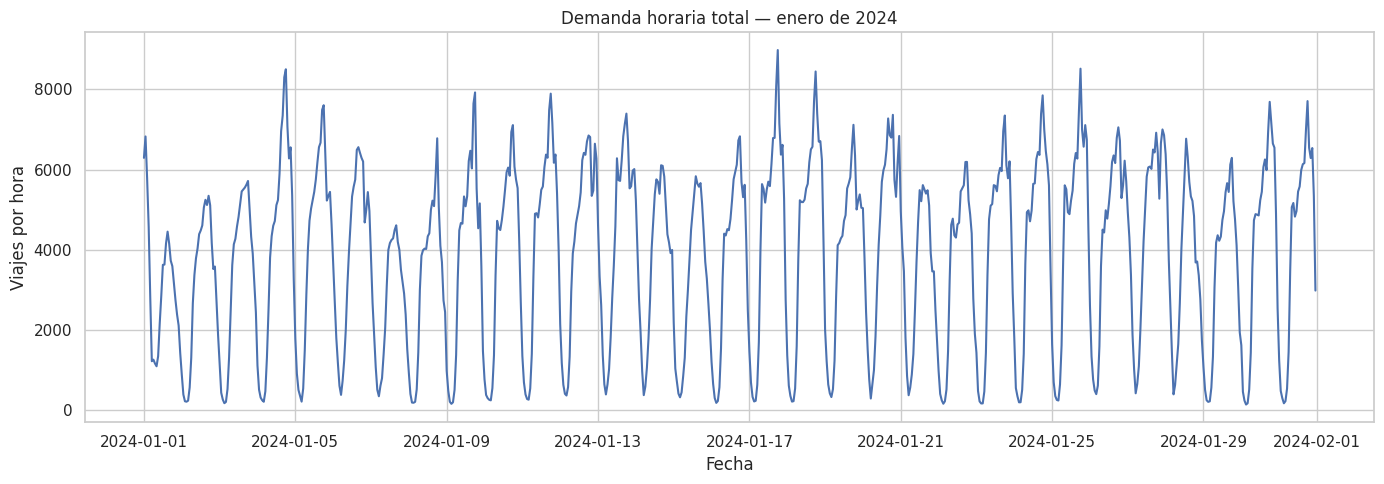

In [38]:
# ============================================================
# 13. COMPORTAMIENTO GENERAL DE LA DEMANDA
# ============================================================

# Sumamos la demanda de todas las zonas para observar
# el comportamiento horario total del sistema.
demanda_total = (
    demanda.groupby("hora", as_index=False)["viajes"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(
    demanda_total["hora"],
    demanda_total["viajes"]
)
plt.title("Demanda horaria total — enero de 2024")
plt.xlabel("Fecha")
plt.ylabel("Viajes por hora")
plt.tight_layout()
plt.show()


## 8. Modelo base: “igual que hace una semana”

Antes de entrenar Machine Learning se necesita una referencia simple.

Se utilizará `lag_168`:

\[
168 = 7 \times 24
\]

Esto significa que para predecir la demanda de una zona en una determinada hora se utiliza como pronóstico la cantidad de viajes registrada **exactamente una semana antes**.

Un modelo de Machine Learning solo aporta valor si su desempeño se compara con una regla sencilla y razonable como esta.


In [39]:
# ============================================================
# 14. CREACIÓN DEL BASELINE SEMANAL
# ============================================================

# shift(168) desplaza los valores 168 horas dentro de cada zona.
# Gracias al groupby, los datos de una zona nunca se mezclan
# con los datos de otra.
demanda["lag_168"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(168)
)

display(
    demanda[
        ["PULocationID", "hora", "viajes", "lag_168"]
    ].head(175)
)


,PULocationID,hora,viajes,lag_168
0,132,2024-01-01 00:00:00,150,NaN
1,132,2024-01-01 01:00:00,68,NaN
2,132,2024-01-01 02:00:00,21,NaN
3,132,2024-01-01 03:00:00,18,NaN
4,132,2024-01-01 04:00:00,26,NaN
...,...,...,...,...
170,132,2024-01-08 02:00:00,22,21.0
171,132,2024-01-08 03:00:00,29,18.0
172,132,2024-01-08 04:00:00,17,26.0
173,132,2024-01-08 05:00:00,108,58.0


In [40]:
# ============================================================
# 15. DIVISIÓN TEMPORAL PARA EVALUAR EL BASELINE
# ============================================================

# Prueba oficial:
# del 25 al 31 de enero.
test_baseline = demanda[
    (demanda["hora"] >= FECHA_INICIO_TEST) &
    (demanda["lag_168"].notna())
].copy()

y_test_baseline = test_baseline["viajes"]
pred_baseline = test_baseline["lag_168"]

# MAE: error absoluto promedio en viajes por hora.
mae_baseline = mean_absolute_error(
    y_test_baseline,
    pred_baseline
)

# RMSE penaliza con mayor fuerza los errores grandes.
rmse_baseline = np.sqrt(
    mean_squared_error(
        y_test_baseline,
        pred_baseline
    )
)

print(f"MAE baseline:  {mae_baseline:.2f} viajes/hora")
print(f"RMSE baseline: {rmse_baseline:.2f} viajes/hora")


MAE baseline:  11.88 viajes/hora
RMSE baseline: 21.88 viajes/hora


## 9. Primer modelo simple con XGBoost

Este primer modelo todavía **no es el modelo final de cuantiles**.

Su objetivo es comprobar que el flujo completo de preparación y predicción funciona correctamente.

Se utilizarán variables disponibles antes de comenzar el día que se desea pronosticar:

- `lag_24`: demanda de la misma zona hace 24 horas.
- `lag_48`: demanda de la misma zona hace 48 horas.
- `lag_168`: demanda de la misma zona hace una semana.
- `hora_dia`: hora entre 0 y 23.
- `dia_semana`: lunes = 0 hasta domingo = 6.
- `feriado`: identifica el 15 de enero de 2024 (Martin Luther King Jr. Day).

No se utiliza `lag_1`, ya que para pronosticar todo el día siguiente no se conocería la demanda de la hora anterior de ese mismo día futuro.


In [41]:
# ============================================================
# 16. CREACIÓN DE VARIABLES PARA EL MODELO
# ============================================================

# Demanda observada hace 24 horas.
demanda["lag_24"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(24)
)

# Demanda observada hace 48 horas.
demanda["lag_48"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(48)
)

# Variables de calendario.
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek

# El 15 de enero de 2024 fue Martin Luther King Jr. Day.
demanda["feriado"] = (
    demanda["hora"].dt.normalize() == pd.Timestamp("2024-01-15")
).astype(int)

VARIABLES_INICIALES = [
    "lag_24",
    "lag_48",
    "lag_168",
    "hora_dia",
    "dia_semana",
    "feriado"
]

display(
    demanda[
        ["PULocationID", "hora", "viajes"] + VARIABLES_INICIALES
    ].tail()
)


,PULocationID,hora,viajes,lag_24,lag_48,lag_168,hora_dia,dia_semana,feriado
43147,42,2024-01-31 19:00:00,2,1.0,2.0,1.0,19,2,0
43148,42,2024-01-31 20:00:00,4,3.0,2.0,1.0,20,2,0
43149,42,2024-01-31 21:00:00,3,2.0,0.0,0.0,21,2,0
43150,42,2024-01-31 22:00:00,1,0.0,3.0,6.0,22,2,0
43151,42,2024-01-31 23:00:00,1,2.0,0.0,6.0,23,2,0


In [42]:
# ============================================================
# 17. PREPARACIÓN DE TRAIN Y TEST
# ============================================================

# Solo eliminamos filas donde todavía no existe suficiente
# historia para calcular todos los lags.
datos_modelo = demanda.dropna(
    subset=VARIABLES_INICIALES
).copy()

# TRAIN:
# todas las filas disponibles antes del 25 de enero.
train = datos_modelo[
    datos_modelo["hora"] < FECHA_INICIO_TEST
].copy()

# TEST:
# del 25 al 31 de enero.
test = datos_modelo[
    datos_modelo["hora"] >= FECHA_INICIO_TEST
].copy()

X_train = train[VARIABLES_INICIALES]
y_train = train["viajes"]

X_test = test[VARIABLES_INICIALES]
y_test = test["viajes"]

print(f"Filas de entrenamiento: {len(train):,}")
print(f"Filas de prueba:         {len(test):,}")

print("\nPeríodo de entrenamiento:")
print(train["hora"].min(), "→", train["hora"].max())

print("\nPeríodo de prueba:")
print(test["hora"].min(), "→", test["hora"].max())


Filas de entrenamiento: 23,664
Filas de prueba:         9,744

Período de entrenamiento:
2024-01-08 00:00:00 → 2024-01-24 23:00:00

Período de prueba:
2024-01-25 00:00:00 → 2024-01-31 23:00:00


### Parámetros iniciales de XGBoost

Para este primer modelo se utilizan parámetros moderados:

- `n_estimators=200`: cantidad de árboles.
- `max_depth=5`: limita la complejidad de cada árbol.
- `learning_rate=0.05`: aprendizaje gradual.
- `subsample=0.8`: cada árbol utiliza una muestra del 80% de las filas.
- `colsample_bytree=0.8`: cada árbol utiliza una muestra del 80% de las variables.
- `random_state=42`: garantiza reproducibilidad.
- `n_jobs=-1`: utiliza los núcleos disponibles del procesador.

Estos valores **no se presentan como los parámetros óptimos definitivos**. Son una configuración razonable para validar el flujo inicial. El modelo final se ajustará más adelante cuando se implemente el pronóstico probabilístico por cuantiles.


In [43]:
# ============================================================
# 18. ENTRENAMIENTO DEL PRIMER XGBOOST
# ============================================================

modelo_inicial = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Entrenamos exclusivamente con los datos anteriores
# al 25 de enero.
modelo_inicial.fit(
    X_train,
    y_train
)

print("✅ Modelo XGBoost inicial entrenado correctamente.")


✅ Modelo XGBoost inicial entrenado correctamente.


In [44]:
# ============================================================
# 19. EVALUACIÓN DEL MODELO XGBOOST
# ============================================================

# Generamos predicciones para la semana de prueba.
pred_xgb = modelo_inicial.predict(X_test)

# La demanda representa cantidad de viajes y no puede ser negativa.
pred_xgb = np.maximum(pred_xgb, 0)

# Métricas del modelo.
mae_xgb = mean_absolute_error(
    y_test,
    pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        pred_xgb
    )
)

# Evaluamos el baseline EXACTAMENTE sobre las mismas filas
# utilizadas para XGBoost.
pred_baseline_mismo_test = test["lag_168"]

mae_baseline_mismo_test = mean_absolute_error(
    y_test,
    pred_baseline_mismo_test
)

rmse_baseline_mismo_test = np.sqrt(
    mean_squared_error(
        y_test,
        pred_baseline_mismo_test
    )
)

# Tabla comparativa.
resultados = pd.DataFrame({
    "Modelo": [
        "Igual que hace una semana",
        "XGBoost inicial"
    ],
    "MAE": [
        mae_baseline_mismo_test,
        mae_xgb
    ],
    "RMSE": [
        rmse_baseline_mismo_test,
        rmse_xgb
    ]
})

display(resultados.round(2))


,Modelo,MAE,RMSE
0,Igual que hace una semana,11.88,21.88
1,XGBoost inicial,13.07,23.33


In [45]:
# ============================================================
# 20. MEJORA PORCENTUAL RESPECTO AL BASELINE
# ============================================================

mejora_mae_pct = (
    (mae_baseline_mismo_test - mae_xgb)
    / mae_baseline_mismo_test
    * 100
)

mejora_rmse_pct = (
    (rmse_baseline_mismo_test - rmse_xgb)
    / rmse_baseline_mismo_test
    * 100
)

print(f"Mejora de MAE frente al baseline:  {mejora_mae_pct:.2f}%")
print(f"Mejora de RMSE frente al baseline: {mejora_rmse_pct:.2f}%")

if mejora_mae_pct > 0:
    print("\n✅ XGBoost reduce el MAE respecto a la regla semanal.")
else:
    print("\nℹ️ El baseline semanal obtiene un MAE igual o menor.")
    print("Esto no invalida el proyecto: será necesario revisar")
    print("las variables y el modelo probabilístico final.")


Mejora de MAE frente al baseline:  -9.96%
Mejora de RMSE frente al baseline: -6.66%

ℹ️ El baseline semanal obtiene un MAE igual o menor.
Esto no invalida el proyecto: será necesario revisar
las variables y el modelo probabilístico final.


## 10. Visualización de un ejemplo de pronóstico

Para interpretar el comportamiento del modelo se seleccionará automáticamente la zona con mayor cantidad de viajes y se comparará durante la semana de prueba:

- demanda real;
- pronóstico de XGBoost;
- regla “igual que hace una semana”.

Esta gráfica permite detectar visualmente horas donde el modelo subestima o sobreestima la demanda.


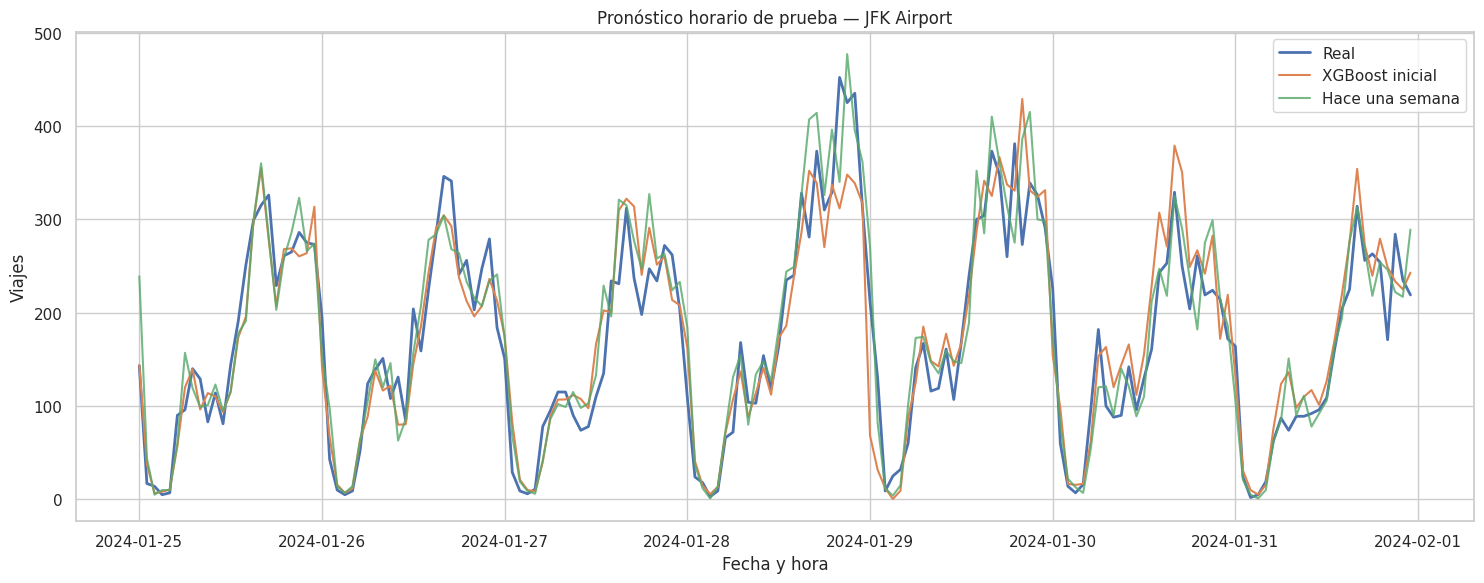

In [46]:
# ============================================================
# 21. COMPARACIÓN VISUAL EN LA ZONA DE MAYOR DEMANDA
# ============================================================

# Identificamos la zona con más viajes durante enero.
zona_ejemplo_id = int(
    zonas_pronostico.iloc[0]["PULocationID"]
)

zona_ejemplo_nombre = zonas_pronostico.iloc[0]["nombre_zona"]

# Filas de prueba de esa zona.
mascara = test["PULocationID"] == zona_ejemplo_id

grafico = test.loc[
    mascara,
    ["hora", "viajes", "lag_168"]
].copy()

# Añadimos las predicciones de XGBoost correspondientes.
grafico["pred_xgb"] = pred_xgb[mascara.to_numpy()]

plt.figure(figsize=(15, 6))

plt.plot(
    grafico["hora"],
    grafico["viajes"],
    label="Real",
    linewidth=2
)

plt.plot(
    grafico["hora"],
    grafico["pred_xgb"],
    label="XGBoost inicial"
)

plt.plot(
    grafico["hora"],
    grafico["lag_168"],
    label="Hace una semana",
    alpha=0.8
)

plt.title(
    f"Pronóstico horario de prueba — {zona_ejemplo_nombre}"
)
plt.xlabel("Fecha y hora")
plt.ylabel("Viajes")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Interpretación parcial

Después de ejecutar el notebook se deben revisar principalmente:

1. El valor del **MAE** de XGBoost frente al baseline semanal.
2. El valor del **RMSE**, que penaliza más los errores grandes.
3. La gráfica de la zona de ejemplo para detectar horas donde el modelo falla.
4. Si la mejora es pequeña, esto no necesariamente significa que el modelo sea inútil. La demanda de taxis puede presentar una fuerte repetición semanal y una regla simple puede ser competitiva.

En la fase siguiente el objetivo será incorporar variables adicionales y convertir el pronóstico en un modelo **probabilístico por cuantiles**, de modo que la aplicación pueda mostrar un rango de incertidumbre y no únicamente una estimación puntual.


## 12. Preparación de datos para `/info`

La primera versión de la API todavía no necesita cargar el modelo para responder `/info`.

Se exportará un archivo con las zonas pronosticables y sus datos principales. FastAPI podrá utilizarlo para devolver:

- identificador de zona;
- nombre;
- distrito.

Posteriormente el endpoint también informará las fechas y los cuantiles disponibles.


In [47]:
# ============================================================
# 22. EXPORTAR INFORMACIÓN PARA LA API
# ============================================================

info_zonas = (
    zonas_pronostico[
        [
            "PULocationID",
            "nombre_zona",
            "distrito",
            "total_viajes"
        ]
    ]
    .sort_values("nombre_zona")
    .reset_index(drop=True)
)

RUTA_INFO_ZONAS = "info_zonas.csv"

info_zonas.to_csv(
    RUTA_INFO_ZONAS,
    index=False
)

print(f"✅ Archivo generado: {RUTA_INFO_ZONAS}")
print(f"Zonas exportadas: {len(info_zonas)}")

display(info_zonas.head())


✅ Archivo generado: info_zonas.csv
Zonas exportadas: 58


,PULocationID,nombre_zona,distrito,total_viajes
0,4,Alphabet City,Manhattan,3568
1,13,Battery Park City,Manhattan,15877
2,24,Bloomingdale,Manhattan,7849
3,41,Central Harlem,Manhattan,6832
4,42,Central Harlem North,Manhattan,3152


In [48]:
# ============================================================
# 23. EXPORTAR MÉTRICAS DEL MODELO INICIAL
# ============================================================

metricas_iniciales = pd.DataFrame({
    "modelo": [
        "baseline_semanal",
        "xgboost_inicial"
    ],
    "mae": [
        mae_baseline_mismo_test,
        mae_xgb
    ],
    "rmse": [
        rmse_baseline_mismo_test,
        rmse_xgb
    ]
})

metricas_iniciales.to_csv(
    "metricas_modelo_inicial.csv",
    index=False
)

print("✅ Archivo generado: metricas_modelo_inicial.csv")
display(metricas_iniciales.round(2))


✅ Archivo generado: metricas_modelo_inicial.csv


,modelo,mae,rmse
0,baseline_semanal,11.88,21.88
1,xgboost_inicial,13.07,23.33


# ✅ Resultado esperado de esta etapa

Al finalizar correctamente este notebook se debe contar con:

- una serie horaria completa con **744 horas por zona**;
- las zonas de pronóstico filtradas con el criterio de **3,000 viajes mínimos**;
- un baseline semanal basado en `lag_168`;
- un primer modelo XGBoost evaluado sobre el período **25–31 de enero**;
- una tabla comparativa de MAE y RMSE;
- una gráfica de ejemplo;
- `info_zonas.csv`, que se utilizará para construir la primera versión de `GET /info`;
- `metricas_modelo_inicial.csv`, útil para documentar el comportamiento del primer modelo.

---

## Próximo paso

Una vez comprobado que este notebook se ejecuta completo sin errores, el siguiente paso será crear:

```text
api/
├── main.py
├── info_zonas.csv
└── requirements.txt
```

y publicar una API mínima en Render que responda:

- `GET /`
- `GET /info`

Después se continuará con el modelo de cuantiles definitivo.
